In [1]:
from typing import TypedDict, Literal, Annotated, List
import operator as op
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

In [2]:
class State(TypedDict):
    expense: int
    comment: Annotated[List[str],op.add]

In [3]:
def manager_node(state: State):
    answer = interrupt({"question":f"Shall the amount {state['expense']} be approved Manager? say yes or no"})
    return {"comment": ["Expense approved by manager"] if answer=="yes" else ["Expense not approved by manager"]}
    

In [4]:
def director_node(state: State):
    answer = interrupt({"question":f"Shall the amount {state['expense']} be approved Director? say yes or no"})
    return {"comment": ["Expense approved by director"] if answer=="yes" else ["Expense not approved by director"]}
       

In [5]:
def judge(state: State):
    return {"comment": [f"Starting the check for expense amount {state['expense']}"]}  

In [6]:
def auto_approve_node(state: State):
    return {"comment": ["Expense auto approved"]}
       

In [7]:
def after_judge(state: State) -> Literal["manager_node", "director_node", "auto_approve_node"]:
    if state["expense"] < 50:
        state["comment"].append("auto-approved")
        print("auto-approved")
        return "auto_approve_node"
    elif state["expense"] < 500:
        state["comment"].append("to be handled by manager")
        print("to be handled by manager")
        return "manager_node"
    else:
        state["comment"].append("to be handled by director")
        print("to be handled by director")
        return "director_node"

In [8]:
def build_graph(checkpointer=None):
    builder = StateGraph(State)
    builder.add_node("judge", judge)
    builder.add_node("manager_node", manager_node)
    builder.add_node("director_node", director_node)
    builder.add_node("auto_approve_node", auto_approve_node)
    builder.add_edge(START, "judge")
    builder.add_conditional_edges("judge", after_judge)
    builder.add_edge("auto_approve_node", END)

    graph = builder.compile(checkpointer=checkpointer)
    return graph


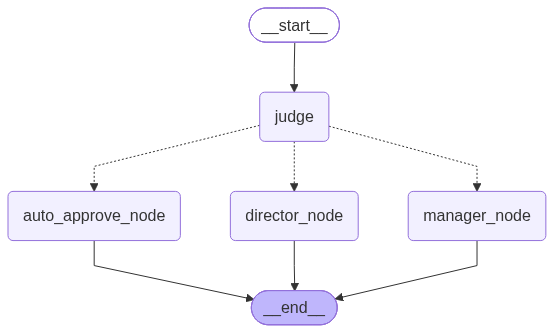

In [18]:
from IPython.display import Image, display

display(Image(build_graph().get_graph().draw_mermaid_png()))

In [19]:
graph = build_graph(InMemorySaver())

In [20]:
config = {"configurable":{"thread_id":"t5"}}

res = graph.invoke({"expense":49,"comment":[]}, config)

auto-approved


In [21]:
res

{'expense': 49,
 'comment': ['Starting the check for expense amount 49',
  'Expense auto approved']}

In [22]:
config = {"configurable":{"thread_id":"t1"}}

res = graph.invoke({"expense":50,"comment":[]}, config)

to be handled by manager


In [23]:
res

{'expense': 50,
 'comment': ['Starting the check for expense amount 50'],
 '__interrupt__': [Interrupt(value={'question': 'Shall the amount 50 be approved Manager? say yes or no'}, id='610e29c4b2508c3f1a1b9555f5fe225a', response_schema=None)]}

In [24]:
final_result = graph.invoke(Command(resume="yes"), config)
final_result

{'expense': 50,
 'comment': ['Starting the check for expense amount 50',
  'Expense approved by manager']}

In [27]:
config = {"configurable":{"thread_id":"t2"}}

res = graph.invoke({"expense":50,"comment":[]}, config)

to be handled by manager


In [28]:
final_result = graph.invoke(Command(resume="no"), config)
final_result

{'expense': 50,
 'comment': ['Starting the check for expense amount 50',
  'Expense not approved by manager']}

PYTESTS

In [37]:

%%writefile test_router.py
import copy
import uuid 

import pytest

@pytest.fixture
def graph():
    """A fresh graph with its own memory for every test."""
    build_graph(InMemorySaver())

@pytest.fixture
def config():
    """A fresh new config"""
    return {"configurable":{"thread_id":str(uuid.uuid4())}}

def run(graph, config, amount):
    return graph.invoke({"expense":amount, "comment":[]}, config)

def visited(graph, config, amount):
    """Names of the nodes that ran, in order."""
    names = []
    for chunk in graph.stream({"expense": amount, "comment": []}, config, stream_mode="updates"):
        names.extend(k for k in chunk if k != "__interrupt__")
    return names


def test_router_does_not_change_the_state():
    state = {"expense": 120, "comment": ["earlier"]}
    before = copy.deepcopy(state)
    after_judge(state)
    assert state == before


# ------------------------------------------------- 1. the router (no graph)

@pytest.mark.parameterize(
    "amount, expected",
    [
        (0, "auto_approve"),
        (49, "auto_approve"),
        (50, "manager"),
        (499,"manager"),
        (500, "director"),
        (501, "director"),
    ],
)
def test_router_picks_the_right_branch(amount, expected):
    assert after_judge({"expense": amount, "comment": []}) == expected

# ------------------------------------------ 2. the whole graph, three paths
def test_small_expense_is_auto_approved_without_pausing(graph, config):
    result = run(graph, config, 49)
    assert "__interrupt__" not in result
    assert result["comment"] == ["Starting the check for expense amount 49", "Expense auto approved"]

def test_manager_path_pauses_then_approves(graph, config):
    paused = run(graph, config, 50)
    assert "Manager" in paused["__interrupt__"][0].value["question"]
    
    final = graph.invoke(Command(resume="yes"), config)
    assert final["comment"][-1] == "Expense approved by manager"

def test_manager_path_can_reject(graph, config):
    run(graph, config, 200)
    final = graph.invoke(Command(resume="no"), config)
    assert final["comment"][-1] == "Expense not approved by manager"
    
def test_large_expense_goes_to_the_director(graph, config):
    paused = run(graph, config, 500)
    assert "Director" in paused["__interrupt__"][0].value["question"]
    final = graph.invoke(Command(resume="yes"), config)
    assert final["comment"][-1] == "Expense approved by director"


def test_path_taken_is_exactly_what_we_expect(graph, config):
    assert visited(graph, config, 49) == ["judge", "auto_approve"]
    
# ------------------------------------------------- 3. threads and memory
def test_different_threads_do_not_share_comments(graph):
    a = {"configurable": {"thread_id": "A"}}
    b = {"configurable": {"thread_id": "B"}}
    run(graph, a, 49)
    result_b = run(graph, b, 49)
    assert result_b["comment"] == ["Checking expense of 49", "Expense auto approved"]


def test_reusing_a_thread_keeps_the_old_comments(graph, config):
    """Documents a behaviour that surprised us: the same thread_id continues the old state."""
    run(graph, config, 49)
    second = run(graph, config, 49)
    assert len(second["comment"]) == 4

Writing test_router.py


============================= test session starts ==============================
collected 0 items                                                              

============================ no tests ran in 0.00s =============================
